# Model Evaluation

## Load Libraries

In [ ]:
# GOOGLE DRIVE
PROJECT_DIR = "/content/drive/MyDrive/FDL Project"

DATA_DIR = f"{PROJECT_DIR}/data/flower_photos"
SPLIT_DIR = f"{PROJECT_DIR}/data/splits"
MODEL_DIR = f"{PROJECT_DIR}/models"
SCRIPT_DIR = f"{PROJECT_DIR}/scripts"
PLOT_DIR = f"{PROJECT_DIR}/plots"
HISTORY_DIR = f"{PROJECT_DIR}/history"

In [ ]:
from google.colab import drive
import os
import glob
import sys
import json
import time
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score, log_loss, confusion_matrix

drive.flush_and_unmount()
drive.mount('/content/drive')

if SCRIPT_DIR not in sys.path:
    sys.path.append(SCRIPT_DIR)

from preprocessing import load_common_datasets

Mounted at /content/drive


## Set Final Models

In [ ]:
final_models = {
    "SCRATCH_v13.0": "rescale_m1_1",
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple": None,
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium": None,
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy": None,
    "MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple": None,
    "ViT_Classifier_v7.0": None,
    "ViT_FineTuned_Classifier_v9.0": None,
}

# Latest checked versions present in models/history:
# - Scratch: SCRATCH_v13.0
# - MobileNetV2 frozen-head comparison: v5.2 clean distributed v3 reduce_lr (simple, medium, heavy)
# - MobileNetV2 light fine-tuned: v6.0 clean distributed v3 reduce_lr, fixed simple head
# - ViT: ViT_Classifier_v7.0
# - ViT fine-tuned: ViT_FineTuned_Classifier_v9.0
TRAIN_FILE_NAME = "train_folds_v3.csv"


## Model Performance Check

### Get Architecture Metrics

In [ ]:
FOLD_TAG = "fold_0"
sorted_model_prefixes = sorted(final_models.keys(), key=len, reverse=True)

# Exact parameter counts audited from the saved fold_0 .keras checkpoints.
# This avoids repeatedly loading large models from Google Drive only to count params,
# which can trigger ConnectionAbortedError in Colab/Drive.
PARAMETER_COUNTS = {
    "SCRATCH_v13.0": {
        "Total Params": 1_687_237,
        "Trainable Params": 1_684_805,
        "Non-Trainable Params": 2_432,
    },
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple": {
        "Total Params": 2_264_389,
        "Trainable Params": 6_405,
        "Non-Trainable Params": 2_257_984,
    },
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium": {
        "Total Params": 2_422_597,
        "Trainable Params": 164_613,
        "Non-Trainable Params": 2_257_984,
    },
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy": {
        "Total Params": 2_619_461,
        "Trainable Params": 361_477,
        "Non-Trainable Params": 2_257_984,
    },
    "MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple": {
        "Total Params": 2_264_389,
        "Trainable Params": 1_201_285,
        "Non-Trainable Params": 1_063_104,
    },
    "ViT_Classifier_v7.0": {
        "Total Params": 85_802_501,
        "Trainable Params": 3_845,
        "Non-Trainable Params": 85_798_656,
    },
    "ViT_FineTuned_Classifier_v9.0": {
        "Total Params": 85_802_501,
        "Trainable Params": 85_802_501,
        "Non-Trainable Params": 0,
    },
}

final_model_files = sorted(
    f
    for f in os.listdir(MODEL_DIR)
    if any(f.startswith(prefix) for prefix in sorted_model_prefixes)
    and FOLD_TAG in f
    and f.endswith(".keras")
)

print("Found models:", final_model_files)
missing_prefixes = [
    prefix for prefix in final_models
    if not any(f.startswith(prefix) for f in final_model_files)
]
if missing_prefixes:
    print("Missing fold_0 checkpoints:", missing_prefixes)

missing_param_counts = [
    prefix for prefix in final_models
    if prefix not in PARAMETER_COUNTS
]
if missing_param_counts:
    raise ValueError(f"Missing parameter counts for: {missing_param_counts}")

model_summary = []

for model_name in final_models:
  counts = PARAMETER_COUNTS[model_name]
  total_params = counts["Total Params"]
  trainable_params = counts["Trainable Params"]
  non_trainable_params = counts["Non-Trainable Params"]

  model_summary.append({
      "Model Architecture": model_name,
      "Total Params": total_params,
      "Trainable Params": trainable_params,
      "Non-Trainable Params": non_trainable_params,
      "Total Params (M)": round(total_params / 1e6, 3),
      "Trainable Params (M)": round(trainable_params / 1e6, 3),
      "Non-Trainable Params (M)": round(non_trainable_params / 1e6, 3),
  })


df_model_archi_specs = pd.DataFrame(model_summary)
print("ARCHITECTURAL SUMMARY")
print(df_model_archi_specs.to_string(index=False))


Found models: ['MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy_fold_0_2026-09-04_11-10-08.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium_fold_0_2026-09-04_11-10-08.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple_fold_0_2026-09-04_11-10-08.keras', 'MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_simple_fold_0_2026-09-06_15-03-17.keras', 'SCRATCH_v13.0_fold_0_2026-09-03_22-38-02.keras', 'ViT_Classifier_v7.0_fold_0_2026-09-04_10-54-59.keras', 'ViT_FineTuned_Classifier_v9.0_fold_0_2026-09-04_11-25-52.keras']
ARCHITECTURAL SUMMARY
                                                     Model Architecture  Total Params  Trainable Params  Non-Trainable Params  Total Params (M)  Trainable Params (M)  Non-Trainable Params (M)
                                                          SCRATCH_v13.0       1687237           1684805                  2432             1.687                 1.685        

### Get Efficiency Metrics

In [ ]:
# Latency helper (single image, batch_size=1)
def measure_latency(
    model, input_shape=(1, 224, 224, 3), num_warmup=15, num_runs=50
):
  dummy_input = tf.random.normal(input_shape)
  for _ in range(num_warmup):
    _ = model(dummy_input, training=False)

  latencies = []
  for _ in range(num_runs):
    t0 = time.perf_counter()
    _ = model(dummy_input, training=False)
    t1 = time.perf_counter()
    latencies.append((t1 - t0) * 1000)  # Convert to ms

  return np.mean(latencies), np.median(latencies)

In [ ]:
model_summary = []

for model_filename in final_model_files:
  model_name = next(
      prefix for prefix in sorted_model_prefixes if model_filename.startswith(prefix)
  )

  model_path = os.path.join(MODEL_DIR, model_filename)
  model = tf.keras.models.load_model(model_path)

  # Latency benchmark
  mean_lat, p50_lat = measure_latency(model)
  fps = 1000.0 / mean_lat

  model_summary.append({
      "Model Architecture": model_name,
      "Latency Mean (ms)": round(mean_lat, 2),
      "Latency P50 (ms)": round(p50_lat, 2),
      "Throughput (FPS)": round(fps, 1),
  })

  del model
  keras.backend.clear_session()

df_model_specs = pd.DataFrame(model_summary)
print("EFFICIENCY SUMMARY")
print(df_model_specs.to_string(index=False))


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path)

EFFICIENCY SUMMARY
                                                     Model Architecture  Latency Mean (ms)  Latency P50 (ms)  Throughput (FPS)
     MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy             181.13            164.77               5.5
    MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium             167.34            155.81               6.0
    MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple             243.36            230.75               4.1
MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple             171.77            160.73               5.8
                                                          SCRATCH_v13.0              18.92             18.51              52.8
                                                    ViT_Classifier_v7.0             243.86            227.75               4.1
                                          ViT_FineTuned_Classifier_v9.0             239.77  

### Convergence Statistics

In [ ]:
def find_epochs_to_convergence(history_data, patience=5, min_delta=1e-3):
  if len(history_data) > 0 and "phase" in history_data[0]:
    grouped_folds = {}
    for entry in history_data:
        fold_id = entry["fold"]
        if fold_id not in grouped_folds:
            grouped_folds[fold_id] = []
        grouped_folds[fold_id].extend(entry["history"]["val_loss"])

    normalized_data = [
        {"val_loss": grouped_folds[f]} for f in sorted(grouped_folds.keys())
    ]
  else:
    normalized_data = history_data

  results = []

  for fold_idx, history in enumerate(normalized_data):
    val_losses = np.array(history["val_loss"])
    total_epochs = len(val_losses)

    # Best Validation Loss Epoch (1-indexed)
    best_epoch = int(np.argmin(val_losses)) + 1
    best_val_loss = float(val_losses[best_epoch - 1])

    # Patience-based Convergence (Early Stopping Simulation)
    conv_epoch_patience = total_epochs
    best_so_far = float("inf")
    wait = 0

    for epoch_idx, loss in enumerate(val_losses, start=1):
      if best_so_far - loss > min_delta:
        best_so_far = loss
        wait = 0
      else:
        wait += 1
        if wait >= patience:
            # Converged at the point where improvement halted
            conv_epoch_patience = epoch_idx - patience
            break

    results.append(
      {
          "fold": fold_idx + 1,
          "total_epochs": total_epochs,
          "best_loss_epoch": best_epoch,
          "best_val_loss": round(best_val_loss, 4),
          "patience_converged_epoch": conv_epoch_patience,
      }
    )

  return results

In [ ]:
history_sources = [
    {
        "model": "SCRATCH_v13.0",
        "path": f"{HISTORY_DIR}/SCRATCH_v13.0_history.json",
        "head_type": "N/A",
    },
    {
        "model": "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple",
        "path": f"{HISTORY_DIR}/MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_history.json",
        "head_type": "simple",
    },
    {
        "model": "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium",
        "path": f"{HISTORY_DIR}/MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_history.json",
        "head_type": "medium",
    },
    {
        "model": "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy",
        "path": f"{HISTORY_DIR}/MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_history.json",
        "head_type": "heavy",
    },
    {
        "model": "MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple",
        "path": f"{HISTORY_DIR}/MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_history.json",
        "head_type": "simple",
    },
    {
        "model": "ViT_Classifier_v7.0",
        "path": f"{HISTORY_DIR}/ViT_Classifier_v7.0_history.json",
        "head_type": "N/A",
    },
    {
        "model": "ViT_FineTuned_Classifier_v9.0",
        "path": f"{HISTORY_DIR}/ViT_FineTuned_Classifier_v9.0_history.json",
        "head_type": "N/A",
    },
]

fold_stats = []

for source in history_sources:
    if not os.path.exists(source["path"]):
        print(f"Missing history file: {source['path']}")
        continue

    with open(source["path"], "r") as f:
        history_data = json.load(f)

    if source["head_type"] != "N/A" and len(history_data) > 0 and "head_type" in history_data[0]:
        history_data = [
            item for item in history_data
            if item.get("head_type") == source["head_type"]
        ]

    results = find_epochs_to_convergence(history_data, patience=7)

    for fold_res in results:
        fold_res["model"] = source["model"]
        fold_res["head_type"] = source["head_type"]
        fold_stats.append(fold_res)

df_results = pd.DataFrame(fold_stats)

columns_order = [
    "model",
    "head_type",
    "fold",
    "total_epochs",
    "best_loss_epoch",
    "best_val_loss",
    "patience_converged_epoch",
]
df_results = df_results[columns_order]


In [ ]:
for model_name, group in df_results.groupby("model"):
    print(f"\n{model_name}:")
    for _, row in group.iterrows():
        print(
            f"  Fold {row['fold']}: Best Epoch {row['best_loss_epoch']}/{row['total_epochs']} "
            f"(Val Loss: {row['best_val_loss']:.4f}) | Converged: Epoch {row['patience_converged_epoch']}"
        )

    avg_best = group["best_loss_epoch"].mean()
    avg_conv = group["patience_converged_epoch"].mean()
    avg_loss = group["best_val_loss"].mean()
    print(
        f"  -> Average: Best Ep {avg_best:.1f}, Conv Ep {avg_conv:.1f}, Min Val Loss {avg_loss:.4f}"
    )


MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy:
  Fold 1: Best Epoch 10/16 (Val Loss: 0.2844) | Converged: Epoch 16
  Fold 2: Best Epoch 5/11 (Val Loss: 0.3319) | Converged: Epoch 11
  Fold 3: Best Epoch 5/11 (Val Loss: 0.2955) | Converged: Epoch 11
  Fold 4: Best Epoch 11/17 (Val Loss: 0.2735) | Converged: Epoch 17
  Fold 5: Best Epoch 7/13 (Val Loss: 0.2045) | Converged: Epoch 13
  -> Average: Best Ep 7.6, Conv Ep 13.6, Min Val Loss 0.2780

MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium:
  Fold 1: Best Epoch 10/16 (Val Loss: 0.2837) | Converged: Epoch 6
  Fold 2: Best Epoch 14/20 (Val Loss: 0.3225) | Converged: Epoch 20
  Fold 3: Best Epoch 11/17 (Val Loss: 0.2940) | Converged: Epoch 10
  Fold 4: Best Epoch 20/26 (Val Loss: 0.2949) | Converged: Epoch 19
  Fold 5: Best Epoch 20/26 (Val Loss: 0.2123) | Converged: Epoch 26
  -> Average: Best Ep 15.0, Conv Ep 16.2, Min Val Loss 0.2815

MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_

## Val Set Evaluation

In [ ]:
df_main = pd.read_csv(f"{SPLIT_DIR}/{TRAIN_FILE_NAME}", dtype={'image_path': str, 'fold': int})
unique_folds = sorted(df_main['fold'].unique())
print(f"Found folds: {unique_folds}. \n")


Found folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]. 



### Get Validation Predictions

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
fold_results = {}

for current_fold in unique_folds:
    FOLD_TAG = f"fold_{current_fold}"

    final_model_files = [
        f for f in os.listdir(MODEL_DIR)
        if any(f.startswith(prefix) for prefix in sorted_model_prefixes)
        and FOLD_TAG in f
        and f.endswith(".keras")
    ]
    print("Found models:", final_model_files)

    for model_filename in final_model_files:
        model_name = next(
            prefix for prefix in sorted_model_prefixes if model_filename.startswith(prefix)
        )
        norm_type = final_models[model_name]

        _, val_ds, _, class_names = load_common_datasets(
            project_dir=PROJECT_DIR,
            val_fold=current_fold,
            img_size=224,
            batch_size=32,
            normalization=norm_type,
            train_file_name=TRAIN_FILE_NAME,
            shuffle_train=False
        )

        model = tf.keras.models.load_model(f"{MODEL_DIR}/{model_filename}")

        # Keep features and labels strictly aligned in one pass
        images_list, labels_list = [], []
        for x_batch, y_batch in val_ds:
            images_list.append(x_batch)
            labels_list.append(y_batch.numpy())

        x_val = tf.concat(images_list, axis=0)
        y_true = np.concatenate(labels_list, axis=0)

        # Predict directly on the aligned feature array
        y_prob = model.predict(x_val, batch_size=32, verbose=1)

        fold_results.setdefault(model_name, {})[current_fold] = {
            "y_true": y_true,
            "y_prob": y_prob,
            "y_pred": np.argmax(y_prob, axis=1)
        }

Found models: ['SCRATCH_v13.0_fold_0_2026-09-03_22-38-02.keras', 'ViT_Classifier_v7.0_fold_0_2026-09-04_10-54-59.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple_fold_0_2026-09-04_11-10-08.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium_fold_0_2026-09-04_11-10-08.keras', 'ViT_FineTuned_Classifier_v9.0_fold_0_2026-09-04_11-25-52.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy_fold_0_2026-09-04_11-10-08.keras', 'MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_simple_fold_0_2026-09-06_15-03-17.keras']
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 216ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path)

18/18 ━━━━━━━━━━━━━━━━━━━━ 14s 446ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 148ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 406 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 402 variables. 
  saveable.load_own_variables(weights_store.get(inner_pa

18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 399ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 137ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step
Found models: ['SCRATCH_v13.0_fold_1_2026-09-03_22-38-02.keras', 'ViT_Classifier_v7.0_fold_1_2026-09-04_10-54-59.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple_fold_1_2026-09-04_11-10-08.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium_fold_1_2026-09-04_11-10-08.keras', 'ViT_FineTuned_Classifier_v9.0_fold_1_2026-09-04_11-25-52.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy_fold_1_2026-09-04_11-10-08.keras', 'MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_simple_fold_1_2026-09-06_15-03-17.keras']
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path)

... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path)

18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 325ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 131ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 402 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


18/18 ━━━━━━━━━━━━━━━━━━━━ 15s 537ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 156ms/step


### Get Model Prediction Statistics
* Macro F1
* Accuracy
* Balanced Accuracy



In [ ]:
summary_rows = []
all_fold_rows = []

for model_name, folds in fold_results.items():
    fold_f1_list = []
    fold_acc_list = []
    fold_bal_acc_list = []

    for fold_key, data in folds.items():
        y_true = data["y_true"]
        y_pred = data["y_pred"]

        # If y_pred contains probabilities/logits instead of class indices:
        if y_pred.ndim > 1:
            y_pred = np.argmax(y_pred, axis=1)

        f1 = f1_score(y_true, y_pred, average="macro")
        acc = accuracy_score(y_true, y_pred)
        bal_acc = balanced_accuracy_score(y_true, y_pred)

        fold_f1_list.append(f1)
        fold_acc_list.append(acc)
        fold_bal_acc_list.append(bal_acc)

        all_fold_rows.append(
            {
                "Model": model_name,
                "Fold": str(fold_key),
                "Macro_F1": f1,
                "Accuracy": acc,
                "Balanced_Accuracy": bal_acc,
            }
        )

    # Calculate summary stats for the model
    summary_rows.append(
        {
        "Model": model_name,
        "Mean_Macro_F1": round(np.mean(fold_f1_list), 4),
        "Std_Macro_F1": round(np.std(fold_f1_list), 4),
        "Mean_Accuracy": round(np.mean(fold_acc_list), 4),
        "Std_Accuracy": round(np.std(fold_acc_list), 4),
        "Mean_Balanced_Accuracy": round(np.mean(fold_bal_acc_list), 4),
        "Std_Balanced_Accuracy": round(np.std(fold_bal_acc_list), 4),
        }
    )



In [ ]:
# 1. Detailed per-fold results table
df_folds = pd.DataFrame(all_fold_rows)
print("PER-FOLD RESULTS")
print(df_folds.to_string(index=False))

# 2. Aggregated CV comparison table
df_summary = pd.DataFrame(summary_rows)
print("\n5-FOLD CV SUMMARY (Mean ± Std)")
print(df_summary.to_string(index=False))

PER-FOLD RESULTS
                                                                  Model Fold  Macro_F1  Accuracy  Balanced_Accuracy
                                                          SCRATCH_v13.0    0  0.819982  0.822695           0.821690
                                                          SCRATCH_v13.0    1  0.846199  0.849291           0.848337
                                                          SCRATCH_v13.0    2  0.825607  0.827709           0.825937
                                                          SCRATCH_v13.0    3  0.837472  0.840142           0.840842
                                                          SCRATCH_v13.0    4  0.828638  0.833037           0.830738
                                                    ViT_Classifier_v7.0    0  0.977769  0.978723           0.978089
                                                    ViT_Classifier_v7.0    1  0.970771  0.971631           0.970936
                                                    ViT

### Get Outlier Folds (If there is Any)

In [ ]:
for model_name in final_models:
  print(f"==== Outlier Folds of {model_name} ====")
  mean_f1 = df_summary[df_summary["Model"] == model_name]["Mean_Macro_F1"].values[0]
  std_f1 = df_summary[df_summary["Model"] == model_name]["Std_Macro_F1"].values[0]
  threshold = mean_f1 - (1.5 * std_f1)

  outlier_folds = df_folds[
     (df_folds["Model"] == model_name) & (df_folds["Macro_F1"] < threshold)
 ]

  print("Outlier Folds:", outlier_folds["Fold"].tolist())

==== Outlier Folds of SCRATCH_v13.0 ====
Outlier Folds: []
==== Outlier Folds of MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple ====
Outlier Folds: ['1']
==== Outlier Folds of MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium ====
Outlier Folds: ['1']
==== Outlier Folds of MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy ====
Outlier Folds: []
==== Outlier Folds of MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple ====
Outlier Folds: []
==== Outlier Folds of ViT_Classifier_v7.0 ====
Outlier Folds: []
==== Outlier Folds of ViT_FineTuned_Classifier_v9.0 ====
Outlier Folds: []


## Test Set Evaluation

### Get Test Set Predictions

In [ ]:
df_main = pd.read_csv(f"{SPLIT_DIR}/{TRAIN_FILE_NAME}", dtype={'image_path': str, 'fold': int})
unique_folds = sorted(df_main['fold'].unique())
print(f"Found folds: {unique_folds}. \n")

# Use the same latest models for test-set evaluation.
final_models = {
    "SCRATCH_v13.0": "rescale_m1_1",
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple": None,
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium": None,
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy": None,
    "MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple": None,
    "ViT_Classifier_v7.0": None,
    "ViT_FineTuned_Classifier_v9.0": None,
}
sorted_model_prefixes = sorted(final_models.keys(), key=len, reverse=True)


Found folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]. 



In [ ]:
test_results = {}
y_test_true = None

for current_fold in unique_folds:
  FOLD_TAG = f"fold_{current_fold}"

  final_model_files = [
      f
      for f in os.listdir(MODEL_DIR)
      if any(f.startswith(prefix) for prefix in sorted_model_prefixes)
      and FOLD_TAG in f
      and f.endswith(".keras")
  ]
  print("Found models:", final_model_files)

  # Extract test true labels

  for model_filename in final_model_files:
    model_name = next(
        prefix for prefix in sorted_model_prefixes if model_filename.startswith(prefix)
    )

    norm_type = final_models[model_name]
    _, _, test_ds, class_names = load_common_datasets(
      project_dir=PROJECT_DIR,
      val_fold=0,
      img_size=224,
      batch_size=32,
      normalization=norm_type,
      train_file_name=TRAIN_FILE_NAME,
    )

    if y_test_true is None:
      y_test_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)

    model = tf.keras.models.load_model(f"{MODEL_DIR}/{model_filename}")
    y_test_prob = model.predict(test_ds, verbose=1)
    test_results.setdefault(model_name, {})[current_fold] = {
        "y_true": y_test_true,
        "y_prob": y_test_prob,
        "y_pred": np.argmax(y_test_prob, axis=1),
    }

Found models: ['SCRATCH_v13.0_fold_0_2026-09-03_22-38-02.keras', 'ViT_Classifier_v7.0_fold_0_2026-09-04_10-54-59.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple_fold_0_2026-09-04_11-10-08.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium_fold_0_2026-09-04_11-10-08.keras', 'ViT_FineTuned_Classifier_v9.0_fold_0_2026-09-04_11-25-52.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy_fold_0_2026-09-04_11-10-08.keras', 'MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_simple_fold_0_2026-09-06_15-03-17.keras']
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 240ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path)

23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 371ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 174ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 207ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 406 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 402 variables. 
  saveable.load_own_variables(weights_store.get(inner_pa

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 317ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 189ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 194ms/step
Found models: ['SCRATCH_v13.0_fold_1_2026-09-03_22-38-02.keras', 'ViT_Classifier_v7.0_fold_1_2026-09-04_10-54-59.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple_fold_1_2026-09-04_11-10-08.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium_fold_1_2026-09-04_11-10-08.keras', 'ViT_FineTuned_Classifier_v9.0_fold_1_2026-09-04_11-25-52.keras', 'MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy_fold_1_2026-09-04_11-10-08.keras', 'MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_simple_fold_1_2026-09-06_15-03-17.keras']
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 131ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path)

... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path)

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 375ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 152ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 232ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 402 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


23/23 ━━━━━━━━━━━━━━━━━━━━ 18s 559ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 161ms/step


### Get Test Statistics
* Macro F1
* Accuracy
* Balanced Accuracy

In [ ]:
comparison_rows = []
all_single_fold_rows = []

for model_name, folds_dict in test_results.items():
    fold_probs_list = []
    single_fold_f1s = []

    y_test_true = None

    for fold_key, data in folds_dict.items():
        if y_test_true is None:
            y_test_true = data["y_true"]

        y_prob = data["y_prob"]
        y_pred = data["y_pred"]

        # Store probabilities for ensembling
        fold_probs_list.append(y_prob)

        # Compute metrics for this single fold checkpoint on the test set
        fold_f1 = f1_score(y_test_true, y_pred, average="macro")
        fold_acc = accuracy_score(y_test_true, y_pred)
        fold_bal = balanced_accuracy_score(y_test_true, y_pred)

        single_fold_f1s.append(
            (fold_key, fold_f1, fold_acc, fold_bal)
        )  # Track individual scores

        all_single_fold_rows.append(
            {
                "Model": model_name,
                "Fold": str(fold_key),
                "Test_Macro_F1": fold_f1,
                "Test_Accuracy": fold_acc,
                "Test_Balanced_Acc": fold_bal,
            }
        )

    # Identify the Best Single Fold Checkpoint
    # Sort by F1 descending
    best_fold_key, best_f1, best_acc, best_bal = max(
        single_fold_f1s, key=lambda item: item[1]
    )

    # Compute 5-Fold Soft-Voting Ensemble
    # Average softmax probabilities across all folds: shape (5, N_samples, 5) -> (N_samples, 5)
    ensemble_prob = np.mean(fold_probs_list, axis=0)
    ensemble_pred = np.argmax(ensemble_prob, axis=1)

    ens_f1 = f1_score(y_test_true, ensemble_pred, average="macro")
    ens_acc = accuracy_score(y_test_true, ensemble_pred)
    ens_bal = balanced_accuracy_score(y_test_true, ensemble_pred)

    # Record comparison summary
    comparison_rows.append(
        {
            "Model": model_name,
            "Best_Single_Fold": str(best_fold_key),
            "Best_Fold_F1": round(best_f1, 4),
            "Ensemble_F1": round(ens_f1, 4),
            "F1_Gain (Δ)": round(ens_f1 - best_f1, 4),
            "Ensemble_Accuracy": round(ens_acc, 4),
            "Ensemble_Balanced_Acc": round(ens_bal, 4),
        }
    )

In [ ]:
print("=== INDIVIDUAL FOLD CHECKPOINTS ON TEST SET ===")
df_all_folds = pd.DataFrame(all_single_fold_rows)
print(df_all_folds.to_string(index=False))

print("\n=== SINGLE BEST FOLD vs. 5-FOLD ENSEMBLE COMPARISON ===")
df_comparison = pd.DataFrame(comparison_rows)
print(df_comparison.to_string(index=False))

=== INDIVIDUAL FOLD CHECKPOINTS ON TEST SET ===
                                                                  Model Fold  Test_Macro_F1  Test_Accuracy  Test_Balanced_Acc
                                                          SCRATCH_v13.0    0       0.805237       0.807640           0.805971
                                                          SCRATCH_v13.0    1       0.816536       0.818554           0.817745
                                                          SCRATCH_v13.0    2       0.809826       0.811733           0.807666
                                                          SCRATCH_v13.0    3       0.816587       0.819918           0.816145
                                                          SCRATCH_v13.0    4       0.824786       0.828104           0.824861
                                                    ViT_Classifier_v7.0    0       0.968788       0.969986           0.968699
                                                    ViT_Classifier_v7.

### 5 Class Statistics

In [ ]:
from sklearn.metrics import classification_report
target_names = class_names if "class_names" in locals() else None

for model_name, folds_dict in test_results.items():
  # 1. Collect predicted probability arrays across all 5 folds
  fold_probs = [data["y_prob"] for data in folds_dict.values()]
  y_test_true = next(iter(folds_dict.values()))["y_true"]

  # 2. Average the probabilities (Soft-Voting Ensemble)
  ensemble_prob = np.mean(fold_probs, axis=0)
  ensemble_pred = np.argmax(ensemble_prob, axis=1)

  # 3. Generate the per-class classification report
  print("=" * 60)
  print(f"5-FOLD ENSEMBLE CLASSIFICATION REPORT: {model_name}")
  print("=" * 60)

  report_text = classification_report(
      y_true=y_test_true,
      y_pred=ensemble_pred,
      target_names=target_names,
      digits=4,
  )
  print(report_text)
  print("\n")

5-FOLD ENSEMBLE CLASSIFICATION REPORT: SCRATCH_v13.0
              precision    recall  f1-score   support

     class_0     0.8699    0.7937    0.8301       160
     class_1     0.8103    0.8778    0.8427       180
     class_2     0.7846    0.8095    0.7969       126
     class_3     0.9091    0.8633    0.8856       139
     class_4     0.7615    0.7734    0.7674       128

    accuracy                         0.8267       733
   macro avg     0.8271    0.8236    0.8245       733
weighted avg     0.8291    0.8267    0.8271       733



5-FOLD ENSEMBLE CLASSIFICATION REPORT: ViT_Classifier_v7.0
              precision    recall  f1-score   support

     class_0     0.9623    0.9563    0.9592       160
     class_1     0.9889    0.9889    0.9889       180
     class_2     0.9764    0.9841    0.9802       126
     class_3     1.0000    0.9784    0.9891       139
     class_4     0.9313    0.9531    0.9421       128

    accuracy                         0.9727       733
   macro avg     

## Audit Failures


In [ ]:
class_names = ["tulips", "dandelion", "daisy", "sunflowers", "roses"]

print("=== CLASS LABEL LEGEND ===")
for idx, name in enumerate(class_names):
  print(f"  Class: {name:<14} ---> Numeric Label: {idx}")

=== CLASS LABEL LEGEND ===
  Class: tulips         ---> Numeric Label: 0
  Class: dandelion      ---> Numeric Label: 1
  Class: daisy          ---> Numeric Label: 2
  Class: sunflowers     ---> Numeric Label: 3
  Class: roses          ---> Numeric Label: 4


=== SCRATCH_v13.0: All 127 Misclassifications ===


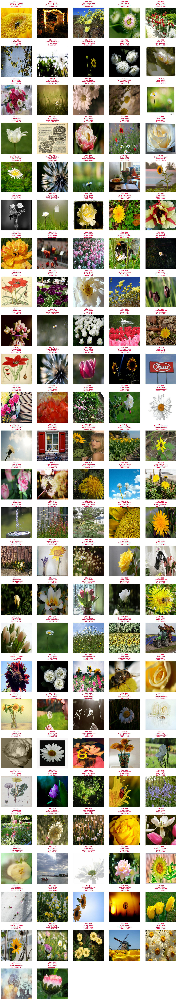

=== ViT_Classifier_v7.0: All 20 Misclassifications ===


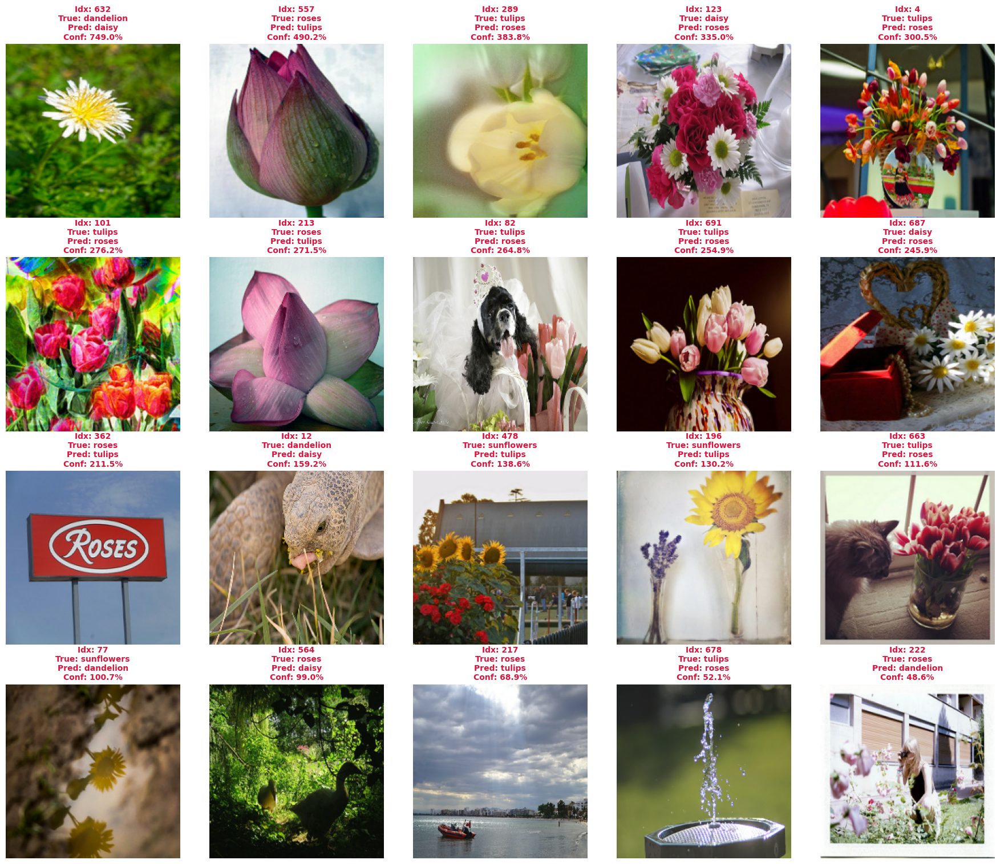

=== MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple: All 73 Misclassifications ===


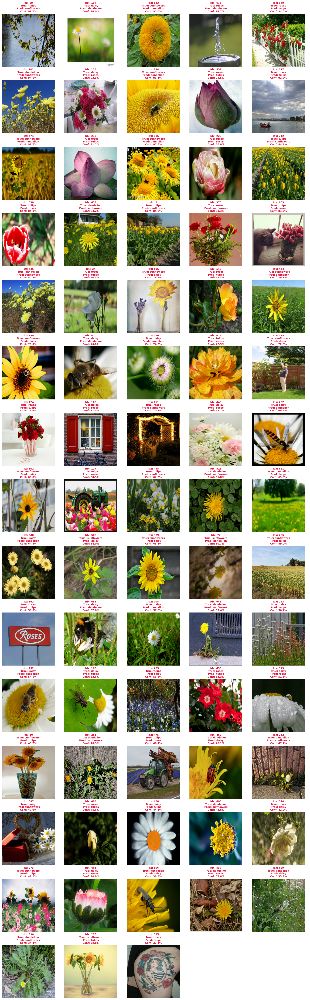

=== MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium: All 74 Misclassifications ===


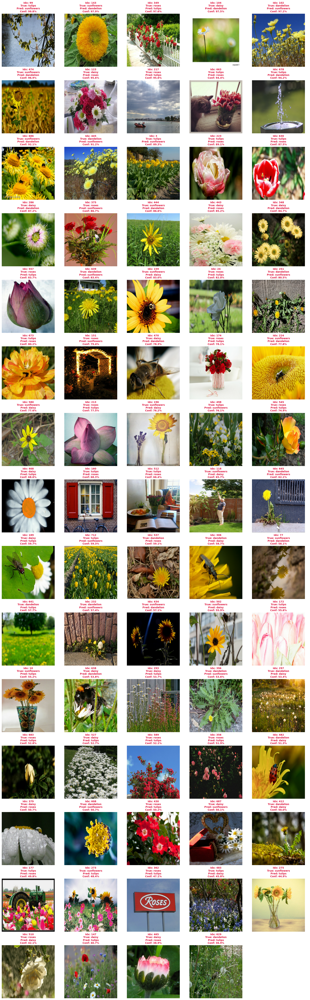

=== ViT_FineTuned_Classifier_v9.0: All 9 Misclassifications ===


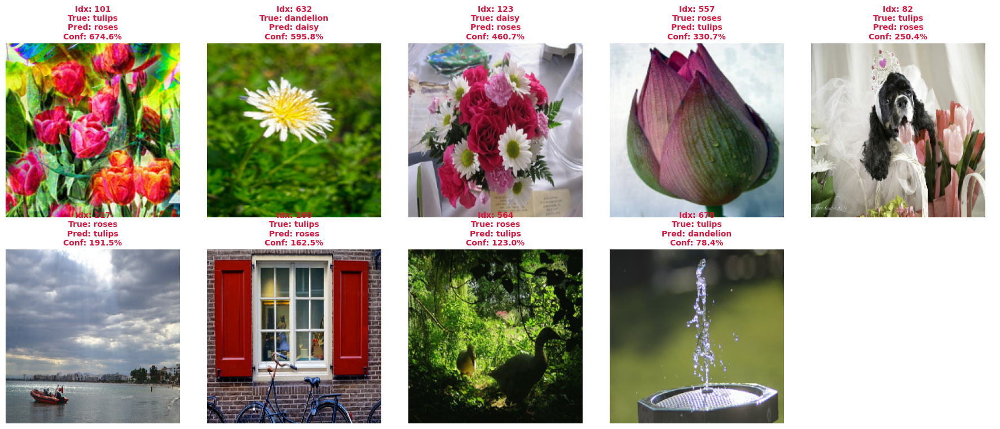

=== MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy: All 77 Misclassifications ===


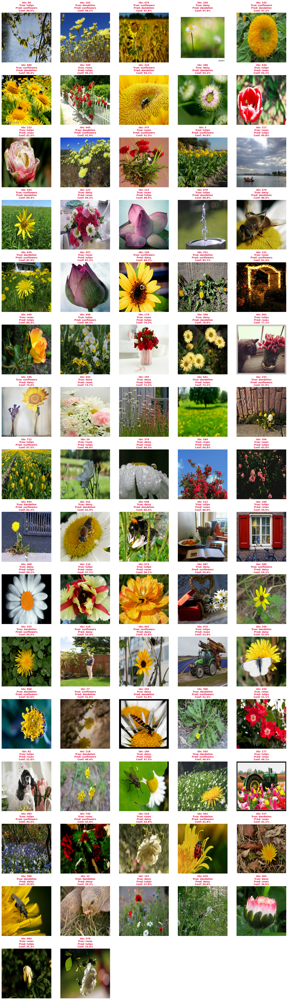

=== MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple: All 68 Misclassifications ===


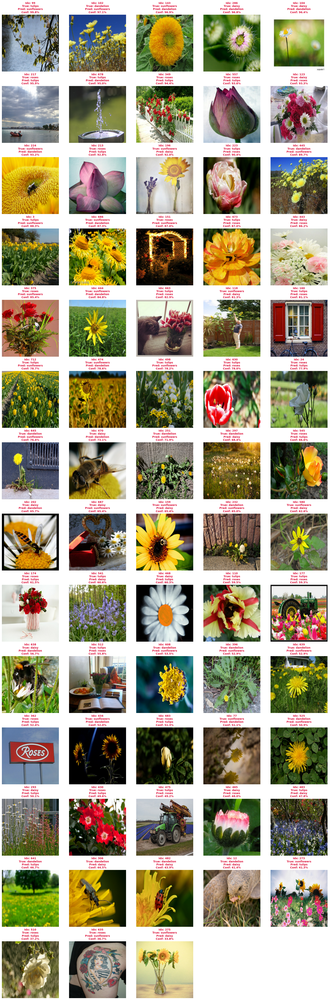

In [ ]:
test_images = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
test_images_vis = np.clip(test_images, 0, 255).astype(np.uint8)

for model_name, folds_dict in test_results.items():
    # Denormalize depending on model preprocessing

    # Compute 5-fold ensemble probabilities
    fold_probs = [data["y_prob"] for data in folds_dict.values()]
    y_test_true = next(iter(folds_dict.values()))["y_true"]
    ensemble_prob = np.mean(fold_probs, axis=0)

    # Convert one-hot vectors to class index integers if needed
    if y_test_true.ndim > 1:
        y_test_true = np.argmax(y_test_true, axis=1)

    y_pred = np.argmax(ensemble_prob, axis=1)
    confidences = np.max(ensemble_prob, axis=1)

    # Find all mistake indices
    mistake_indices = np.where(y_pred != y_test_true)[0]
    sorted_mistakes = mistake_indices[np.argsort(-confidences[mistake_indices])]

    total_errors = len(sorted_mistakes)
    print(f"=== {model_name}: All {total_errors} Misclassifications ===")

    if total_errors == 0:
        print("0 errors found on the test set!\n")
        continue

    cols = 5
    rows = int(np.ceil(total_errors / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(18, 3.8 * rows))
    axes = np.atleast_1d(axes).ravel()

    for i, idx in enumerate(sorted_mistakes):
        axes[i].imshow(test_images_vis[idx])

        # Extract integer labels
        true_idx = int(y_test_true[idx])
        pred_idx = int(y_pred[idx])

        # Lookup flower names directly
        true_name = class_names[true_idx]
        pred_name = class_names[pred_idx]
        conf_str = f"{confidences[idx] * 100:.1f}%"

        axes[i].set_title(
            f"Idx: {idx}\nTrue: {true_name}\nPred: {pred_name}\nConf: {conf_str}",
            fontsize=10,
            color="crimson",
            fontweight="bold",
        )
        axes[i].axis("off")

    # Turn off remaining unused subplot axes
    for j in range(total_errors, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

### Normalized Confusion Matrix

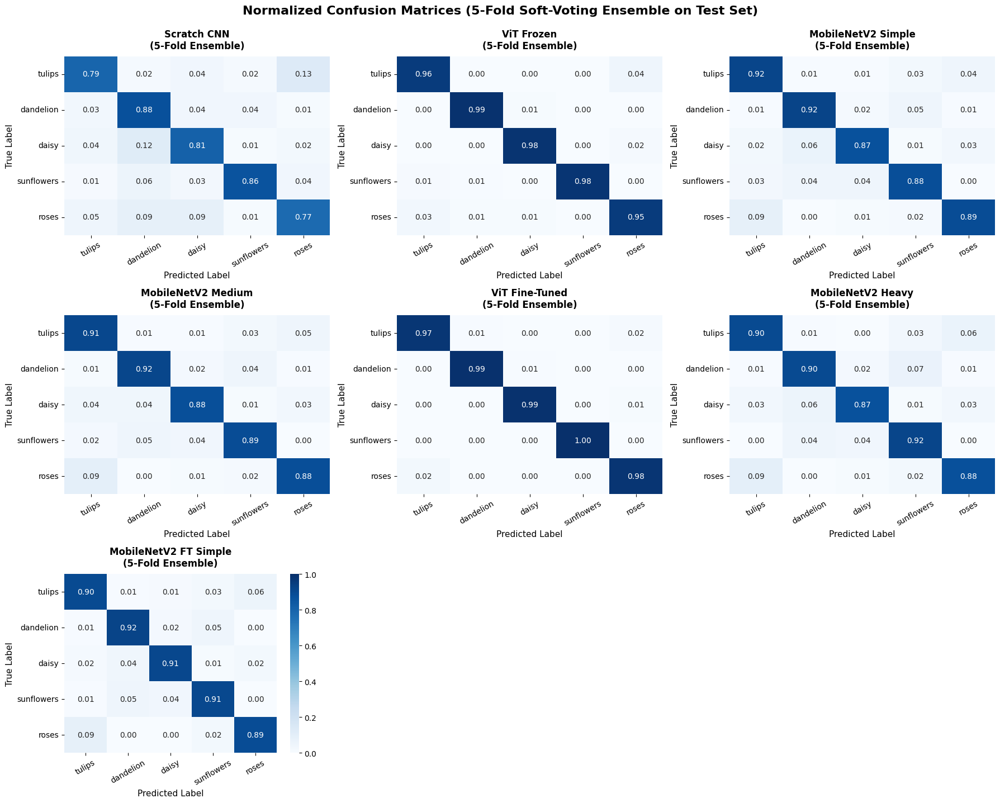

In [30]:
class_names = ["tulips", "dandelion", "daisy", "sunflowers", "roses"]

plot_names = {
    "SCRATCH_v13.0": "Scratch CNN",
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_simple": "MobileNetV2 Simple",
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_medium": "MobileNetV2 Medium",
    "MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_heavy": "MobileNetV2 Heavy",
    "MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple": "MobileNetV2 FT Simple",
    "ViT_Classifier_v7.0": "ViT Frozen",
    "ViT_FineTuned_Classifier_v9.0": "ViT Fine-Tuned",
}

n_models = len(test_results)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.8 * n_rows))
axes = np.array(axes).reshape(-1)

for idx, (model_name, folds_dict) in enumerate(test_results.items()):
    ax = axes[idx]

    # Collect predicted probabilities and ground truth
    fold_probs = [data["y_prob"] for data in folds_dict.values()]
    y_test_true = next(iter(folds_dict.values()))["y_true"]

    # Soft-Voting Ensemble (Average Probabilities)
    ensemble_prob = np.mean(fold_probs, axis=0)
    ensemble_pred = np.argmax(ensemble_prob, axis=1)

    # Compute row-normalized confusion matrix
    cm = confusion_matrix(
        y_true=y_test_true,
        y_pred=ensemble_pred,
        normalize="true",
    )

    # Plot Heatmap
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=(idx == n_models - 1),
        vmin=0.0,
        vmax=1.0,
        ax=ax,
        annot_kws={"size": 10},
    )

    title = plot_names.get(model_name, model_name) + "\n(5-Fold Ensemble)"
    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("True Label", fontsize=11)
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

# Hide unused subplots, if the grid has more panels than models.
for ax in axes[n_models:]:
    ax.axis("off")

plt.suptitle(
    "Normalized Confusion Matrices (5-Fold Soft-Voting Ensemble on Test Set)",
    fontsize=16,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout()
plt.show()


### Log Loss

In [ ]:
# 1. Per-Fold Log Loss (to compute Mean ± Std across CV folds)
for model_name, folds_dict in test_results.items():
    fold_losses = []
    for fold_id, data in folds_dict.items():
        loss = log_loss(y_true=data["y_true"], y_pred=data["y_prob"])
        fold_losses.append(loss)

    print(
        f"{model_name} Log Loss: {np.mean(fold_losses):.4f} ± {np.std(fold_losses):.4f}"
    )

print(f"\n")

# 2. Ensemble Log Loss (using the averaged ensemble_prob)
for model_name, folds_dict in test_results.items():
    fold_probs = [data["y_prob"] for data in folds_dict.values()]
    y_test_true = next(iter(folds_dict.values()))["y_true"]

    ensemble_prob = np.mean(fold_probs, axis=0)

    ens_loss = log_loss(y_true=y_test_true, y_pred=ensemble_prob)
    print(f"{model_name} 5-Fold Ensemble Log Loss: {ens_loss:.4f}")

## GRAD-CAM

In [31]:
def display_gradcam(img_path, heatmap, alpha=0.4):
  img = cv2.imread(img_path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

  heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
  heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
  heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

  superimposed_img = np.uint8(img * (1 - alpha) + heatmap_colored * alpha)

  plt.figure(figsize=(8, 4))
  plt.subplot(1, 2, 1)
  plt.imshow(img)
  plt.title("Original Image")
  plt.axis("off")

  plt.subplot(1, 2, 2)
  plt.imshow(superimposed_img)
  plt.title("Grad-CAM Overlay")
  plt.axis("off")
  plt.tight_layout()
  plt.show()

### SCRATCH

In [32]:
def get_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
  with tf.GradientTape() as tape:
      # Pass input sequentially through layers
      x = img_array
      conv_outputs = None

      for layer in model.layers:
          x = layer(x)
          if layer.name == last_conv_layer_name:
              conv_outputs = x
              # Explicitly record gradients for intermediate conv activations
              tape.watch(conv_outputs)

      preds = x
      if pred_index is None:
          pred_index = tf.argmax(preds[0])
      class_channel = preds[:, pred_index]

  if conv_outputs is None:
      raise ValueError(f"Layer '{last_conv_layer_name}' was not found in the model.")

  # Compute gradients of class score w.r.t target layer activations
  grads = tape.gradient(class_channel, conv_outputs)
  pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

  conv_outputs = conv_outputs[0]
  heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
  heatmap = tf.squeeze(heatmap)

  heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
  return heatmap.numpy()

Target layer automatically found: conv2d_3


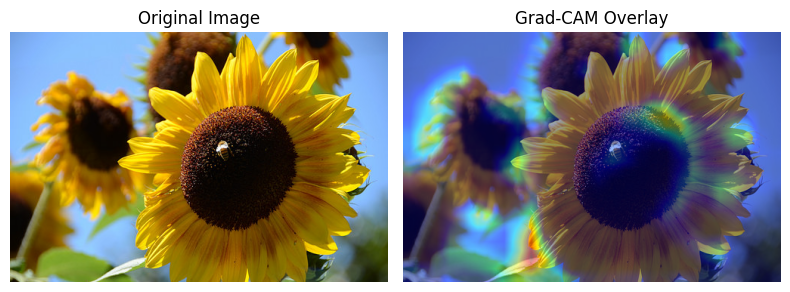

In [33]:
model = tf.keras.models.load_model(f"{MODEL_DIR}/SCRATCH_v13.0_fold_0_2026-09-03_22-38-02.keras")

dummy_input = tf.zeros((1, 224, 224, 3))
_ = model(dummy_input)

for layer in reversed(model.layers):
  if isinstance(layer, tf.keras.layers.Conv2D):
    target_layer_name = layer.name
    print(f"Target layer automatically found: {target_layer_name}")
    break

img_path = f"{DATA_DIR}/sunflowers/20342824594_9740b7b160.jpg"

img_bytes = tf.io.read_file(img_path)
img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
img = tf.image.resize(img, [224, 224], method="bilinear")
img = tf.cast(img, tf.float32)

img = (img / 127.5) - 1.0     # normalization="rescale_m1_1"

img_array = tf.expand_dims(img, axis=0)

# Generate and plot Grad-CAM
heatmap = get_gradcam_heatmap(img_array, model, last_conv_layer_name=target_layer_name)
display_gradcam(img_path, heatmap)

### MOBILE-NET

In [34]:
def make_gradcam_heatmap(img_array, model, pred_index=None):
  img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

  with tf.GradientTape() as tape:
    x = img_tensor
    backbone_output = None

    # Sequential forward execution through existing layers
    for layer in model.layers:
      # Skip InputLayer
      if isinstance(layer, tf.keras.layers.InputLayer):
        continue

      # Pass training=False to disable dropout / augmentation
      try:
        x = layer(x, training=False)
      except (TypeError, ValueError):
        x = layer(x)

      # Tap the 4D feature maps right at mobilenetv2_backbone
      if layer.name == "mobilenetv2_backbone":
        backbone_output = x
        tape.watch(backbone_output)

    preds = x
    if pred_index is None:
        pred_index = tf.argmax(preds[0])
    class_channel = preds[:, pred_index]

  # Compute gradients of target class w.r.t backbone activations (shape: [1, 7, 7, 1280])
  grads = tape.gradient(class_channel, backbone_output)

  # Global spatial average pooling of gradients (shape: [1280])
  pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

  # Weight feature channels by pooled gradients
  backbone_output = backbone_output[0]
  heatmap = backbone_output @ pooled_grads[..., tf.newaxis]
  heatmap = tf.squeeze(heatmap)

  # ReLU and safe normalization
  heatmap = tf.maximum(heatmap, 0.0) / (tf.math.reduce_max(heatmap) + 1e-10)
  return heatmap.numpy()

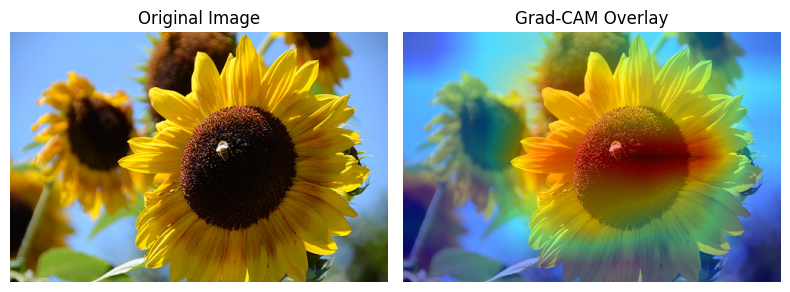

In [35]:
model = tf.keras.models.load_model(f"{MODEL_DIR}/MobileNetV2_v6.0_light_finetuning_clean_distributed_v3_reduce_lr_simple_simple_fold_0_2026-09-06_15-03-17.keras")

# 2. Preprocess input image
img_path = f"{DATA_DIR}/sunflowers/20342824594_9740b7b160.jpg"
img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# 3. Compute and display
heatmap = make_gradcam_heatmap(img_array, model)
display_gradcam(img_path, heatmap)

### ViT

In [36]:
def make_vit_gradcam_heatmap(img_array, model, pred_index=None):
    img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

    with tf.GradientTape() as tape:
        # 1. Forward pass
        backbone = model.get_layer("vi_t_backbone")
        tokens = backbone(img_tensor, training=False)
        tape.watch(tokens)

        x = model.get_layer("output_dropout")(tokens, training=False)
        logits = model.get_layer("predictions")(x, training=False)

        # Grab classification vector
        if len(logits.shape) == 3:
            preds = logits[:, 0, :]
        else:
            preds = logits

        # Work with pre-softmax logits or log of predictions to avoid vanishing gradient
        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]).numpy())

        # Taking log helps if the layer outputs softmax probabilities
        target_score = preds[:, pred_index]

    # 2. Gradient w.r.t the 197 tokens: [1, 197, 768]
    grads = tape.gradient(target_score, tokens)

    # 3. Discard [CLS] token, keep only 196 patch tokens: [196, 768]
    patch_tokens = tokens[0, 1:, :]
    patch_grads = grads[0, 1:, :]

    # 4. Element-wise product of activations and gradients per patch
    # This measures how much each feature in each patch contributed directly
    patch_cam = tf.reduce_sum(patch_tokens * patch_grads, axis=-1)  # shape: [196]

    # 5. Reshape 196 -> 14x14 grid
    grid_size = int(np.sqrt(patch_cam.shape[0]))  # 14
    heatmap = tf.reshape(patch_cam, (grid_size, grid_size))

    # 6. Apply ReLU (keep positive contributors to the sunflower class)
    heatmap = tf.maximum(heatmap, 0.0)

    # 7. Robust min-max scaling to 0.0 - 1.0
    min_val = tf.math.reduce_min(heatmap)
    max_val = tf.math.reduce_max(heatmap)

    if max_val - min_val > 1e-7:
        heatmap = (heatmap - min_val) / (max_val - min_val)
    else:
        heatmap = tf.zeros_like(heatmap)

    return heatmap.numpy()

In [37]:
def display_gradcam(img_path, heatmap, alpha=0.4):
    # 1. Load image safely
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"Could not load image at path: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. Ensure heatmap is a 2D float32 array
    heatmap = np.asarray(heatmap, dtype=np.float32)
    if heatmap.ndim != 2:
        heatmap = np.squeeze(heatmap)

    # 3. Resize heatmap to match image dimensions (width, height)
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    # 4. Convert to 8-bit unsigned integer (0-255) for colormap
    heatmap_uint8 = np.uint8(255 * np.clip(heatmap_resized, 0, 1))
    heatmap_colored = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    # 5. Blend heatmap with original image
    superimposed_img = np.uint8(img * (1 - alpha) + heatmap_colored * alpha)

    # 6. Plot side-by-side
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(superimposed_img)
    plt.title("ViT Grad-CAM Overlay")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/saving/serialization_lib.py:749: UserWarning: `compile()` was not called as part of model loading because the model's `compile()` method is custom. All subclassed Models that have `compile()` overridden should also override `get_compile_config()` and `compile_from_config(config)`. Alternatively, you can call `compile()` manually after loading.
  instance.compile_from_config(compile_config)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 406 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 402 variables. 
  saveable.load_own_variables(weights_store.get(inner_pa

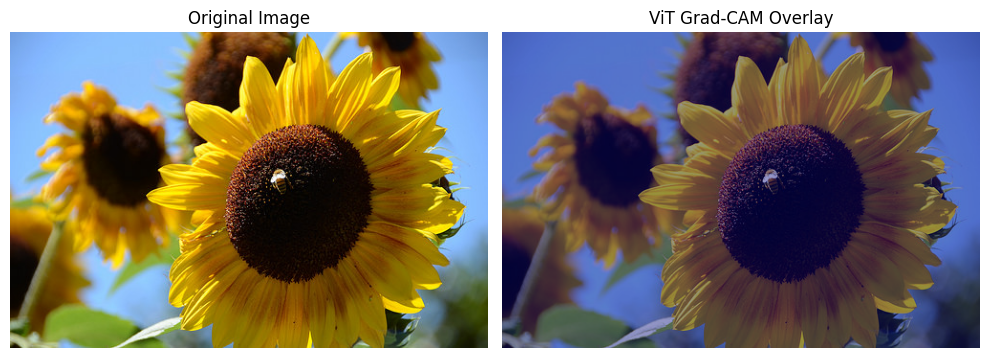

In [38]:
model = tf.keras.models.load_model(f"{MODEL_DIR}/ViT_FineTuned_Classifier_v9.0_fold_0_2026-09-04_11-25-52.keras")

# Preprocess input image
img_path = f"{DATA_DIR}/sunflowers/20342824594_9740b7b160.jpg"
img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Compute and display
heatmap = make_vit_gradcam_heatmap(img_array, model)
display_gradcam(img_path, heatmap)

## Final Test Set Evaluation - Selected Model Only

The final test set is used only after model selection. Here we evaluate the selected final model: frozen ViT (`ViT_Classifier_v7.0`).


In [ ]:
FINAL_TEST_MODEL = "ViT_Classifier_v7.0"
FINAL_TEST_DISPLAY_NAME = "ViT Frozen"
FINAL_TEST_NORMALIZATION = None

# Rebuild fold list from the CV split file.
df_main = pd.read_csv(
    f"{SPLIT_DIR}/{TRAIN_FILE_NAME}",
    dtype={"image_path": str, "fold": int},
)
unique_folds = sorted(df_main["fold"].unique())
print(f"Selected final model: {FINAL_TEST_MODEL}")
print(f"Found folds: {unique_folds}")

# Load the held-out test set once. The val_fold value does not affect the test split.
_, _, final_test_ds, class_names = load_common_datasets(
    project_dir=PROJECT_DIR,
    val_fold=0,
    img_size=224,
    batch_size=32,
    normalization=FINAL_TEST_NORMALIZATION,
    train_file_name=TRAIN_FILE_NAME,
    shuffle_train=False,
)

y_test_true = np.concatenate([y.numpy() for _, y in final_test_ds], axis=0)

final_test_probs = []
final_test_fold_rows = []

for current_fold in unique_folds:
    fold_tag = f"fold_{current_fold}"
    matching_files = sorted(
        f for f in os.listdir(MODEL_DIR)
        if f.startswith(FINAL_TEST_MODEL)
        and fold_tag in f
        and f.endswith(".keras")
    )

    if len(matching_files) != 1:
        raise ValueError(
            f"Expected exactly one checkpoint for {FINAL_TEST_MODEL} {fold_tag}, "
            f"found {len(matching_files)}: {matching_files}"
        )

    model_filename = matching_files[0]
    model_path = os.path.join(MODEL_DIR, model_filename)
    print(f"Evaluating {model_filename}")

    model = tf.keras.models.load_model(model_path, compile=False)
    y_prob = model.predict(final_test_ds, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

    final_test_probs.append(y_prob)
    final_test_fold_rows.append({
        "Model": FINAL_TEST_DISPLAY_NAME,
        "Checkpoint": model_filename,
        "Fold": current_fold,
        "Test Loss": log_loss(
            y_test_true,
            y_prob,
            labels=np.arange(len(class_names)),
        ),
        "Test Accuracy": accuracy_score(y_test_true, y_pred),
        "Test Macro F1": f1_score(y_test_true, y_pred, average="macro"),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test_true, y_pred),
    })

    del model
    keras.backend.clear_session()

# Final prediction by 5-fold soft voting over the selected model checkpoints.
ensemble_prob = np.mean(final_test_probs, axis=0)
ensemble_pred = np.argmax(ensemble_prob, axis=1)

final_test_summary = pd.DataFrame([{
    "Final Model": FINAL_TEST_DISPLAY_NAME,
    "Checkpoint Strategy": "5-fold soft-voting ensemble",
    "Test Loss": log_loss(
        y_test_true,
        ensemble_prob,
        labels=np.arange(len(class_names)),
    ),
    "Test Accuracy": accuracy_score(y_test_true, ensemble_pred),
    "Test Macro F1": f1_score(y_test_true, ensemble_pred, average="macro"),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test_true, ensemble_pred),
}])

final_test_folds = pd.DataFrame(final_test_fold_rows)

print("\nFINAL TEST SET - INDIVIDUAL FOLD CHECKPOINTS")
print(final_test_folds.to_string(index=False))

print("\nFINAL TEST SET - SELECTED MODEL")
print(final_test_summary.to_string(index=False))

print("\nClassification report - selected final model")
print(classification_report(
    y_test_true,
    ensemble_pred,
    target_names=class_names,
    digits=4,
))


In [ ]:
final_cm = confusion_matrix(
    y_true=y_test_true,
    y_pred=ensemble_pred,
    normalize="true",
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    final_cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0.0,
    vmax=1.0,
)
plt.title(
    f"Final Test Set - {FINAL_TEST_DISPLAY_NAME}\n5-Fold Soft-Voting Ensemble",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=30)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
